# 07 - Jev under increasing attack strength

Evaluate **Jev 1.13.0** using fixed label descriptions and no demonstrations. The test covers all 3,080 BANKING77 and 500 TREC examples: clean text once, plus homoglyph, invisible, compatibility and mixed attacks at **5%, 10%, 20%, 40% and 75%**, attack seed 13. All **75,180 rows** are required. Composition is excluded because it changes no inputs.

**Inputs:** Processed data, attacks and baseline predictions from notebooks 01–04.  
**Outputs:** Metric CSVs, a Jev strength plot and cached predictions.

**`RUN_LIVE = False` uses cached responses from `artifacts/jev/responses/`; the ZIP excludes this cache.** Paid requests require `RUN_LIVE = True` and `TYPESAFE_API_KEY` in the environment or ignored `.env.local` file. `JEV_OFFLINE=1` always disables live requests. Run one copy at a time; missing or invalid responses stop the evaluation.


In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import datetime as dt
import hashlib
import json
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yaml
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text())
PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
JEV_DIR = ROOT / 'artifacts/jev'
RUN_LIVE, WORKERS = False, 8
MODEL, ENDPOINT = 'jev-1.13.0', 'https://api.typesafe.ai/v1/systemone'
FAMILIES = ['homoglyph', 'invisible', 'compatibility', 'mixed']
CONDITIONS = ['clean'] + FAMILIES
STRENGTH, ATTACK_SEED = 0.20, 13  #original comparison, retained for the old exports
STRENGTHS = [0.05, 0.10, 0.20, 0.40, 0.75]
COUNTS = {'banking77': 3080, 'trec': 500}
BASELINES = ['word_tfidf', 'char_tfidf', 'bpe_tfidf', 'distilbert']
MODEL_NAMES = dict(zip(BASELINES + ['jev'], ['Word TF-IDF', 'Character TF-IDF', 'BPE TF-IDF', 'DistilBERT', 'Jev (zero-shot)']))
KEYS = ['dataset', 'example_id', 'attack', 'strength', 'attack_seed']

def require(condition, message):
    if not condition:
        raise ValueError(message)

def canonical_bytes(value):
    #keep the original Unicode bytes and the existing cache key format
    return json.dumps(value, sort_keys=True, ensure_ascii=False, separators=(',', ':'), allow_nan=False).encode('utf-8')

def digest(value):
    return hashlib.sha256(canonical_bytes(value)).hexdigest()
def read_api_key():
    if os.environ.get('TYPESAFE_API_KEY'):
        return os.environ['TYPESAFE_API_KEY']
    env_file = ROOT / '.env.local'
    if env_file.exists():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.strip().partition('=')
            if separator and name == 'TYPESAFE_API_KEY':
                value = value.strip()
                if len(value) >= 2 and value[0] == value[-1] and value[0] in {'"', "'"}:
                    value = value[1:-1]
                return value or None
    return None


## Match the test inputs

Pair attacked inputs with their clean counterparts and ground truth (gt) labels. The API receives only the text and the fixed question; gt labels stay local for scoring.


In [2]:
def load_inputs():
    data = pd.read_parquet(PATHS['processed_data'])
    attacks = pd.read_parquet(PATHS['attacks'])
    clean = data[data.split.eq('test')].copy()
    require(clean.example_id.is_unique and clean.groupby('dataset').size().to_dict() == COUNTS, 'Unexpected clean test rows')
    labels = {}
    for dataset, count in [('banking77', 77), ('trec', 6)]:
        pairs = data[data.dataset.eq(dataset)][['label', 'label_name']].drop_duplicates().sort_values('label')
        require(pairs.label.is_unique and pairs.label_name.is_unique and set(pairs.label) == set(range(count)), 'Invalid label mapping')
        labels[dataset] = dict(pairs.itertuples(index=False, name=None))
    selected = attacks[attacks.attack.isin(FAMILIES) & attacks.strength.isin(STRENGTHS) & attacks.attack_seed.eq(ATTACK_SEED)].copy()
    joined = selected.merge(clean[['dataset', 'example_id', 'text', 'label', 'label_name']],
        on=['dataset', 'example_id'], how='left', validate='many_to_one', suffixes=('', '_expected'))
    require(joined.clean_text.eq(joined.text).all() and joined.label.eq(joined.label_expected).all()
        and joined.label_name.eq(joined.label_name_expected).all(), 'Attack/clean mismatch')
    clean = clean.assign(attack='clean', strength=0.0, attack_seed=-1, changed_count=0)
    columns = KEYS + ['text', 'label', 'label_name', 'changed_count']
    conditions = pd.concat([clean[columns], selected.rename(columns={'attacked_text': 'text'})[columns]], ignore_index=True)
    require(not conditions.duplicated(KEYS).any(), 'Duplicate evaluation rows')
    expected = {(d, a, s): n for d, n in COUNTS.items()
                for a in CONDITIONS for s in ([0.] if a == 'clean' else STRENGTHS)}
    require(conditions.groupby(['dataset', 'attack', 'strength']).size().to_dict() == expected, 'Incomplete evaluation rows')
    return conditions.sort_values(KEYS).reset_index(drop=True), labels

def make_questions(labels):
    trec = {
        'ABBR': 'An abbreviation or the expansion of an abbreviation.',
        'ENTY': 'An entity, such as an animal, object, substance, event or language; not a person, place or numeric value.',
        'DESC': 'A definition, explanation, reason, description or manner of doing something.',
        'HUM': 'A person, group of people, organization, title or description of a person.',
        'LOC': 'A location, such as a country, city, state, mountain or other place.',
        'NUM': 'A numeric answer, such as a count, date, duration, amount, distance, size or measurement.',
    }
    return {
        'banking77': {'type': 'choice',
            'instructions': 'Which banking support intent best describes the customer message in `text`? Select exactly one of the supplied intents.',
            'criteria': {name: name.replace('_', ' ').rstrip('?').lower()
                         for name in labels['banking77'].values()}},
        'trec': {'type': 'choice',
            'instructions': 'What type of answer is sought by the question in `text`? Classify the expected answer type, not its topic. Select exactly one supplied category.',
            'criteria': {name: trec[name] for name in labels['trec'].values()}},
    }


## Reuse cached responses

Cache keys include the model, exact Unicode text and question. Identical requests share a response, and successful responses are saved immediately. At most eight requests run at once; an error stops further batches.

The returned Choice is the prediction. Rounded probabilities can sum to slightly more or less than 1, and their argmax can differ from the Choice. The gt-probability is the probability assigned to the gt label.


In [3]:
def validate_response(body, payload):
    answer = body.get('answers', {}).get('classification', {})
    options = payload['questions']['classification']['criteria']
    probabilities = answer.get('probabilities', {})
    require(body.get('model') == payload['model'], 'Returned model differs from requested model')
    require(answer.get('type') == 'choice' and answer.get('choice') in options and set(probabilities) == set(options), 'Invalid response labels')
    values = np.asarray(list(probabilities.values()), dtype=float)
    require(np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
        and values.sum() > 0 and abs(values.sum() - 1) <= .005 * len(values) + 1e-9, 'Invalid probabilities')
    return answer

def ask(payload, api_key, run_live=False):
    key = digest(payload)
    path = JEV_DIR / 'responses' / f'{key}.json'
    if path.exists():
        record = json.loads(path.read_text())
        require(record['request_hash'] == key and record['payload'] == payload, 'Cache/request mismatch')
    else:
        require(run_live and os.environ.get('JEV_OFFLINE') != '1' and api_key,
                f'Missing response {key[:12]}; live calls require RUN_LIVE=True and TYPESAFE_API_KEY, with offline mode disabled')
        started = time.monotonic()
        response = requests.post(ENDPOINT, data=canonical_bytes(payload), timeout=(30, 90), allow_redirects=False,
            headers={'Authorization': f'Bearer {api_key}', 'Content-Type': 'application/json'})
        require(response.status_code == 200, f'API returned HTTP {response.status_code}; completed responses remain cached')
        body = response.json()
        validate_response(body, payload)
        record = dict(request_hash=key, payload=payload, response=body,
            completed_at=dt.datetime.now(dt.timezone.utc).isoformat(), latency_seconds=time.monotonic()-started, attempts=1)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix('.json.tmp')
        temporary.write_bytes(canonical_bytes(record))
        temporary.replace(path)
    return validate_response(record['response'], payload)

def evaluate(conditions, questions, labels, run_live=False):
    payloads = [{'model': MODEL, 'state': {'text': row.text}, 'questions': {'classification': questions[row.dataset]}}
                for row in conditions.itertuples(index=False)]
    keys = [digest(payload) for payload in payloads]
    jobs = dict(zip(keys, payloads))
    answers, api_key = {}, read_api_key()
    items = list(jobs.items())
    #batch submission keeps a failure from launching thousands more requests
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        for start in range(0, len(items), WORKERS):
            batch = items[start:start + WORKERS]
            futures = [(key, pool.submit(ask, payload, api_key, run_live)) for key, payload in batch]
            answers.update((key, future.result()) for key, future in futures)
    frame = conditions.drop(columns=['text', 'label_name']).rename(columns={'label': 'gt_label'}).copy()
    label_ids = {dataset: {name: i for i, name in mapping.items()} for dataset, mapping in labels.items()}
    frame['prediction'] = [label_ids[row.dataset][answers[key]['choice']] for row, key in zip(conditions.itertuples(index=False), keys)]
    frame['gt_probability'] = [answers[key]['probabilities'][row.label_name] for row, key in zip(conditions.itertuples(index=False), keys)]
    return frame.assign(model='jev', replicate='api', request_hash=keys)


## Score each strength and average the attack families

Calculate accuracy, Macro-F1, score losses and ASR for each family and strength, then average the four families equally. ASR uses only examples correct when clean and stays undefined if there are none.

The 20% CSV exports also include the baselines; the displayed table and plot show Jev.


In [4]:
def load_baselines(conditions):
    expected = conditions[KEYS + ['label', 'changed_count']].rename(columns={'label': 'gt_label'})
    frames = []
    for dataset in COUNTS:
        for model in BASELINES:
            seeds = CONFIG['transformer']['seeds'] if model == 'distilbert' else [CONFIG['project']['root_seed']]
            for seed in seeds:
                frame = pd.read_parquet(PATHS['predictions'] / 'raw' / dataset / model / f'seed_{seed}' / 'none.parquet')
                frame = frame[frame.attack.eq('clean') | (frame.attack.isin(FAMILIES) & frame.strength.eq(STRENGTH) & frame.attack_seed.eq(ATTACK_SEED))]
                require(frame.dataset.eq(dataset).all() and frame.model.eq(model).all()
                    and frame.model_seed.eq(seed).all() and frame.defense.eq('none').all(), 'Wrong baseline file')
                check = expected[expected.dataset.eq(dataset)].merge(frame, on=KEYS, how='outer', validate='one_to_one', indicator=True, suffixes=('_expected', ''))
                require(check._merge.eq('both').all() and check.gt_label.eq(check.gt_label_expected).all()
                    and check.changed_count.eq(check.changed_count_expected).all(), 'Baseline rows do not match')
                require(frame.prediction.isin(expected[expected.dataset.eq(dataset)].gt_label.unique()).all()
                    and frame.correct.eq(frame.gt_label.eq(frame.prediction)).all(), 'Invalid baseline predictions')
                frames.append(frame.assign(replicate=str(seed))[KEYS + ['model', 'replicate', 'gt_label', 'prediction', 'changed_count']])
    return pd.concat(frames, ignore_index=True)

def scores(gt_label, prediction, label_count):
    return np.array([accuracy_score(gt_label, prediction),
        f1_score(gt_label, prediction, labels=range(label_count), average='macro', zero_division=0)])

def metric_tables(predictions, labels):
    rows = []
    for (dataset, model, replicate), frame in predictions.groupby(['dataset', 'model', 'replicate']):
        expected = pd.MultiIndex.from_product([CONDITIONS, frame.example_id.unique()], names=['attack', 'example_id'])
        actual = pd.MultiIndex.from_frame(frame[['attack', 'example_id']])
        require(actual.is_unique and len(actual) == len(expected) and actual.isin(expected).all(), 'Missing or duplicate metric rows')
        clean = frame[frame.attack.eq('clean')].set_index('example_id').sort_index()
        gt_label = clean.gt_label.to_numpy(dtype=int)
        clean_pred = clean.prediction.to_numpy(dtype=int)
        clean_scores = scores(gt_label, clean_pred, len(labels[dataset]))
        clean_correct = gt_label == clean_pred
        for attack in CONDITIONS:
            part = frame[frame.attack.eq(attack)].set_index('example_id').reindex(clean.index)
            require(part.gt_label.notna().all() and np.array_equal(part.gt_label, gt_label), 'Unpaired metric rows')
            prediction = part.prediction.to_numpy(dtype=int)
            accuracy, macro_f1 = scores(gt_label, prediction, len(labels[dataset]))
            asr = (np.mean(prediction[clean_correct] != gt_label[clean_correct]) if clean_correct.any() else np.nan)
            rows.append(dict(dataset=dataset, model=model, replicate=replicate, attack=attack,
                n=len(gt_label), accuracy=accuracy, macro_f1=macro_f1, attack_success_rate=asr,
                accuracy_drop=clean_scores[0] - accuracy, macro_f1_drop=clean_scores[1] - macro_f1,
                coverage=part.changed_count.gt(0).mean()))
    per_seed = pd.DataFrame(rows)
    measures = ['accuracy', 'macro_f1', 'attack_success_rate', 'accuracy_drop', 'macro_f1_drop', 'coverage']
    summary = per_seed.groupby(['dataset', 'model', 'attack'])[measures].agg(['mean', 'std']).fillna(0)
    # Preserve undefined ASR rather than replacing it with zero.
    summary.columns = ['_'.join(column) for column in summary.columns]
    summary = summary.reset_index()
    for (dataset, model, attack), group in per_seed.groupby(['dataset', 'model', 'attack']):
        if group.attack_success_rate.isna().all():
            mask = summary.dataset.eq(dataset) & summary.model.eq(model) & summary.attack.eq(attack)
            summary.loc[mask, ['attack_success_rate_mean', 'attack_success_rate_std']] = np.nan
    aggregate_seed = per_seed[per_seed.attack.ne('clean')].groupby(['dataset', 'model', 'replicate'])[measures].mean().reset_index()
    aggregate = aggregate_seed.groupby(['dataset', 'model'])[measures].agg(['mean', 'std'])
    aggregate.columns = ['_'.join(column) for column in aggregate.columns]
    for column in aggregate.columns:
        if column.endswith('_std'):
            aggregate[column] = aggregate[column].fillna(0)
    return per_seed, summary, aggregate_seed, aggregate.reset_index()

def strength_metric_tables(predictions, labels):
    #Check the whole sweep before showing anything: even a missing whole family must fail.
    require(set(predictions.dataset) == set(COUNTS) and predictions.model.eq('jev').all()
        and predictions.replicate.eq('api').all(), 'Unexpected sweep identity')
    require(not predictions.duplicated(KEYS).any(), 'Duplicate sweep rows')
    expected = {(d, a, s): n for d, n in COUNTS.items()
                for a in CONDITIONS for s in ([0.] if a == 'clean' else STRENGTHS)}
    require(predictions.groupby(['dataset', 'attack', 'strength']).size().to_dict() == expected, 'Incomplete sweep rows')
    require(predictions.loc[predictions.attack.eq('clean'), 'attack_seed'].eq(-1).all()
        and predictions.loc[predictions.attack.ne('clean'), 'attack_seed'].eq(ATTACK_SEED).all(), 'Wrong attack seed')
    parts = []
    for strength in STRENGTHS:
        selected = predictions[predictions.attack.eq('clean') | predictions.strength.eq(strength)]
        #The existing scorer checks matching example IDs and gt labels, and keeps all classes in F1.
        part = metric_tables(selected, labels)[0]
        part['strength'] = np.where(part.attack.eq('clean'), 0., strength)
        parts.append(part if strength == STRENGTHS[0] else part[part.attack.ne('clean')])
    conditions = pd.concat(parts, ignore_index=True).sort_values(['dataset', 'strength', 'attack']).reset_index(drop=True)
    measures = ['accuracy', 'macro_f1', 'accuracy_drop', 'macro_f1_drop', 'attack_success_rate', 'coverage']
    summary = conditions.groupby(['dataset', 'strength'])[measures].mean().reset_index()
    summary['n'] = summary.dataset.map(COUNTS)  #unique test examples; each family uses all of them
    return conditions, summary


In [5]:
conditions, labels = load_inputs()
conditions_20 = conditions[conditions.attack.eq('clean') | conditions.strength.eq(STRENGTH)]
baselines = load_baselines(conditions_20)
jev = evaluate(conditions, make_questions(labels), labels, run_live=RUN_LIVE)
strength_conditions, strength_summary = strength_metric_tables(jev, labels)
jev_20 = jev[jev.attack.eq('clean') | jev.strength.eq(STRENGTH)]
per_seed, summary, aggregate_seed, aggregate = metric_tables(pd.concat([baselines, jev_20], ignore_index=True), labels)
for directory in [PATHS['tables'], PATHS['figures'], JEV_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
jev.to_parquet(JEV_DIR / 'predictions.parquet', index=False)
for name, frame in [('condition_metrics', per_seed), ('condition_summary', summary),
                    ('aggregate_by_seed', aggregate_seed), ('aggregate_summary', aggregate),
                    ('strength_condition_metrics', strength_conditions), ('strength_summary', strength_summary)]:
    frame.to_csv(PATHS['tables'] / f'jev_{name}.csv', index=False)
print(f'{len(jev):,} Jev rows matched; {jev.request_hash.nunique():,} distinct requests.')
strength_summary[['dataset', 'strength', 'accuracy', 'macro_f1', 'macro_f1_drop', 'attack_success_rate']].round(3)


75,180 Jev rows matched; 75,074 distinct requests.


,dataset,strength,accuracy,macro_f1,macro_f1_drop,attack_success_rate
0,banking77,0.00,0.801,0.793,0.000,0.000
1,banking77,0.05,0.798,0.791,0.003,0.013
2,banking77,0.10,0.796,0.789,0.004,0.016
3,banking77,0.20,0.795,0.787,0.006,0.019
4,banking77,0.40,0.792,0.785,0.009,0.025
5,banking77,0.75,0.787,0.780,0.013,0.033
6,trec,0.00,0.944,0.939,0.000,0.000
7,trec,0.05,0.942,0.937,0.002,0.005
8,trec,0.10,0.943,0.937,0.003,0.005
9,trec,0.20,0.946,0.942,-0.002,0.005


## Performance across attack strengths

Each curve starts at the clean score. The dashed line averages the four families' Macro-F1 scores. Small gains can occur when an attack corrects clean mistakes. One attack seed and one cached response per request leave variation across API reruns unmeasured.


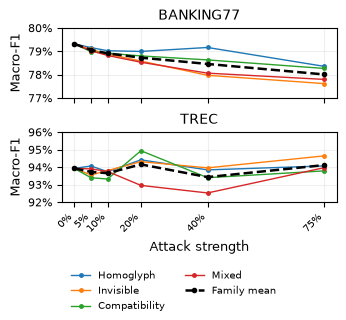

In [6]:
from matplotlib.ticker import PercentFormatter, MultipleLocator

family_names = ['Homoglyph', 'Invisible', 'Compatibility', 'Mixed']
fig, axes = plt.subplots(2, 1, figsize=(3.35, 3.1), sharex=True, sharey=False, constrained_layout=True)
for ax, dataset in zip(axes, COUNTS):
    rows = strength_conditions[strength_conditions.dataset.eq(dataset)]
    clean_f1 = rows.loc[rows.attack.eq('clean'), 'macro_f1'].iloc[0]
    for family, name in zip(FAMILIES, family_names):
        values = rows[rows.attack.eq(family)].set_index('strength').loc[STRENGTHS, 'macro_f1']
        ax.plot([0.] + STRENGTHS, [clean_f1] + list(values), 'o-', ms=2.5, lw=1, label=name)
    means = strength_summary[strength_summary.dataset.eq(dataset)].sort_values('strength')
    ax.plot(means.strength, means.macro_f1, 'o--', color='black', lw=1.8, ms=3, label='Family mean')
    ax.set_title(dataset.upper(), fontsize=10)
    ax.set_ylabel('Macro-F1', fontsize=9)
    #Separate, labeled ranges make these small changes visible in a single column.
    ax.set_ylim(np.floor((rows.macro_f1.min() - .005) * 100) / 100,
                np.ceil((rows.macro_f1.max() + .005) * 100) / 100)
    ax.yaxis.set_major_locator(MultipleLocator(.01))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xticks([0.] + STRENGTHS)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.2)
plt.setp(axes[-1].get_xticklabels(), rotation=45, ha='right', fontsize=7)
axes[-1].set_xlabel('Attack strength', fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2, frameon=False, fontsize=7)
fig.savefig(PATHS['figures'] / 'jev_robustness.pdf', bbox_inches='tight')
plt.show()
